# 04 Benchmark on LinuxONE

Latency per payment, throughput, NNPA, security.

In [1]:
import os, sys, time, json, platform
from pathlib import Path
ROOT = Path.cwd().parent if (Path.cwd().parent / "safepause").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
from safepause import config
print("project:", ROOT, "| machine:", platform.machine(), "| CPUs:", os.cpu_count())

project: /home/ibm-user/shared/safepause | machine: s390x | CPUs: 3


In [2]:
import subprocess, importlib.metadata, glob
def sh(c):
    try: return subprocess.run(c, shell=True, capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception as e: return str(e)
print(sh("lscpu | head -20") or "lscpu not available in container")
cpu = open("/proc/cpuinfo").read() if os.path.exists("/proc/cpuinfo") else ""
print("\nNNPA flag in /proc/cpuinfo:", "nnpa" in cpu)
for pkg in ["ibm-zdnn-plugin", "tensorflow", "xgboost", "llama_cpp_python", "torch_nnpa"]:
    try: print(f"{pkg:18s}", importlib.metadata.version(pkg))
    except Exception: print(f"{pkg:18s} -")

Architecture:                            s390x
CPU op-mode(s):                          32-bit, 64-bit
Byte Order:                              Big Endian
CPU(s):                                  3
On-line CPU(s) list:                     0-2
Vendor ID:                               IBM/S390
Model name:                              -
Machine type:                            9175
Thread(s) per core:                      1
Core(s) per socket:                      1
Socket(s) per book:                      1
Book(s) per drawer:                      1
Drawer(s):                               3
CPU dynamic MHz:                         5508
CPU static MHz:                          5508
BogoMIPS:                                28901.00
Dispatching mode:                        horizontal
Flags:                                   esan3 zarch stfle msa ldisp eimm dfp edat etf3eh highgprs te vx vxd vxe gs vxe2 vxp sort dflt vxp2 nnpa sie
Hypervisor:                              z/VM 7.3.0
Hypervis

## Latency for one payment (features + xgboost + lstm + rules)

single payment, full hybrid pipeline: p50 0.99 ms | p95 1.18 ms | p99 1.30 ms
XGBoost part alone: p50 0.107 ms


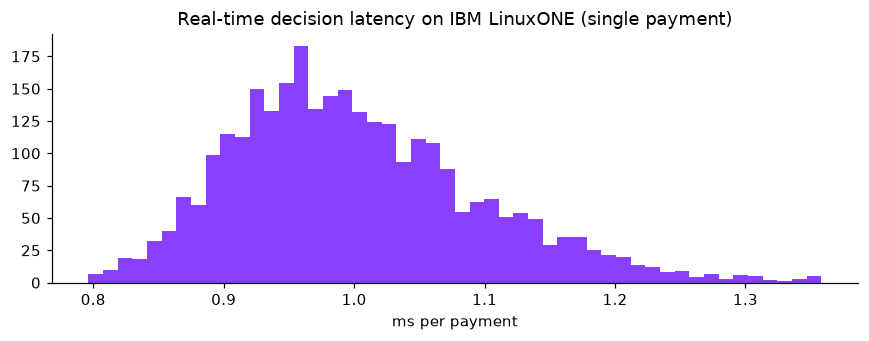

In [3]:
from safepause.features import FeatureEngine, gather_sequences
from safepause.scorer import Scorer
eng = FeatureEngine.load(config.ENGINE_STATE)
scorer = Scorer()
stream = pd.read_csv(config.STREAM_CSV, dtype={"merchant": str, "mcc": str, "city": str, "state": str, "use_chip": str, "errors": str}).fillna({"errors": "", "use_chip": "", "state": "NA"})
secs = pd.to_datetime(stream.ts).to_numpy().astype("datetime64[s]").astype(np.int64)
N = min(3000, len(stream)); lat, lat_x = [], []
for i in range(N):
    r = stream.iloc[i]
    t0 = time.perf_counter()
    f, seq = eng.compute(int(r.user), int(secs[i]), r.amount, r.merchant, r.mcc, r.city, r.use_chip, r.errors, r.state)
    out = scorer.score(f, seq, explain=False)
    lat.append((time.perf_counter() - t0) * 1000)
    t1 = time.perf_counter(); scorer.predict_xgb(f.reshape(1, -1)); lat_x.append((time.perf_counter() - t1) * 1000)
lat = np.array(lat)
print(f"single payment, full hybrid pipeline: p50 {np.median(lat):.2f} ms | p95 {np.percentile(lat,95):.2f} ms | p99 {np.percentile(lat,99):.2f} ms")
print(f"XGBoost part alone: p50 {np.median(lat_x):.3f} ms")
plt.figure(figsize=(8, 3.2)); plt.hist(lat[lat < np.percentile(lat, 99.5)], bins=50, color="#8a3ffc")
plt.xlabel("ms per payment"); plt.title("Real-time decision latency on IBM LinuxONE (single payment)")
plt.tight_layout(); plt.savefig(config.FIGURES / "04_latency.png", bbox_inches="tight"); plt.show()

## Batch throughput

In [4]:
d = np.load(config.DATASET_NPZ); X, prev_idx = d["X"], d["prev_idx"]
te = np.arange(int(d["test_start"]), len(X))
rows = []
for bs in (1, 64, 512, 2048):
    idx = te[:bs]; S = gather_sequences(X, prev_idx, idx); Xb = X[idx]
    scorer.predict_seq(S); scorer.predict_xgb(Xb)  # warm-up
    reps = max(3, 2000 // bs)
    t0 = time.perf_counter()
    for _ in range(reps): scorer.predict_xgb(Xb)
    tx = (time.perf_counter() - t0) / reps
    t0 = time.perf_counter()
    for _ in range(reps): scorer.predict_seq(S)
    tl = (time.perf_counter() - t0) / reps
    rows.append({"batch": bs, "XGBoost ms": tx * 1000, "LSTM (NNPA) ms": tl * 1000,
                 "XGBoost payments/s": bs / tx, "LSTM payments/s": bs / tl})
bench = pd.DataFrame(rows).round(2); display(bench)
bench.to_csv(config.ARTIFACTS / "benchmark.csv", index=False)

,batch,XGBoost ms,LSTM (NNPA) ms,XGBoost payments/s,LSTM payments/s
0,1,0.08,0.72,12009.37,1381.90
1,64,0.27,0.85,236098.71,75541.31
2,512,1.36,1.71,376464.78,298548.02
3,2048,5.02,8.16,408060.12,250889.56


## Security

In [5]:
from safepause.store import pseudonym
print("raw customer id 1234  ->", pseudonym(1234, "c"), "(keyed HMAC-SHA256, key file permissions:",
      oct(config.SECRET_FILE.stat().st_mode & 0o777), ")")
print("LLM runs locally, no payment data goes to external services")
print("API: optional API key, request size limit, input checks, stdlib http server")
print("Decision log stores pseudonyms only:", config.DB_PATH)

raw customer id 1234  -> c07fb9b04e7 (keyed HMAC-SHA256, key file permissions: 0o600 )
LLM runs locally, no payment data goes to external services
API: optional API key, request size limit, input checks, stdlib http server
Decision log stores pseudonyms only: /home/ibm-user/shared/safepause/artifacts/safepause.db
